# Investigate Hotel Business using Data Visualization

## Stage 0: Problem Statement

### 1. Why Customer Booking Behaviour Matters
A hotel's revenue depends on how many guests book and how many of those bookings are later cancelled. Understanding booking behaviour helps a hotel make better decisions in four areas:
- **Pricing:** Raise rates in high-demand months and offer discounts in quiet months.
- **Staffing:** Plan staff levels according to expected demand.
- **Overbooking:** Use cancellation patterns to reduce the number of rooms left empty.
- **Marketing and policy:** Decide which cancellation terms and offers suit which type of guest.

### 2. Business Questions
This project is built around three questions:
1. Which hotel type (City Hotel or Resort Hotel) do customers book most often?
2. Does the length of stay affect the booking cancellation rate?
3. Does lead time (the number of days between booking and arrival) affect the cancellation rate?

### 3. Objective
The main deliverable of this project is a Jupyter Notebook that cleans the hotel bookings dataset, uses visualizations to reveal booking and cancellation patterns, and gives the hotel manager data-driven recommendations to reduce revenue lost to cancellations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries ready!")

Libraries ready!


In [2]:
df = pd.read_csv(r"C:\Users\HP\Desktop\hotel project FA\hotel_bookings_data.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_weekdays_nights,adults,...,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status
0,Resort Hotel,0,342,2017,September,27,1,0,0,2,...,3,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
1,Resort Hotel,0,737,2017,September,27,1,0,0,2,...,4,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
2,Resort Hotel,0,7,2017,September,27,1,0,1,1,...,0,No Deposit,NaN,NaN,0,Personal,75.0,0,0,Check-Out
3,Resort Hotel,0,13,2017,September,27,1,0,1,1,...,0,No Deposit,304.0,NaN,0,Personal,75.0,0,0,Check-Out
4,Resort Hotel,0,14,2017,September,27,1,0,2,2,...,0,No Deposit,240.0,NaN,0,Personal,98.0,0,1,Check-Out


In [3]:
print("Shape:", df.shape)
print("Years:", df["arrival_date_year"].min(), "to", df["arrival_date_year"].max())

Shape: (119390, 29)
Years: 2017 to 2019


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_weekdays_nights        119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
df["children"] = df["children"].fillna(0)
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)
df["city"] = df["city"].fillna("Unknown")

print(df.isnull().sum().sum())

0


In [6]:
print("Duplicates:", df.duplicated().sum())
print("Shape before:", df.shape)

df = df.drop_duplicates()

print("Shape after:", df.shape)

Duplicates: 33261
Shape before: (119390, 29)
Shape after: (86129, 29)


In [7]:
print(df["meal"].value_counts())

meal
Breakfast     67088
No Meal        9442
Dinner         8798
Undefined       454
Full Board      347
Name: count, dtype: int64


In [8]:
df["meal"] = df["meal"].replace("Undefined", "No Meal")
print(df["meal"].value_counts())

meal
Breakfast     67088
No Meal        9896
Dinner         8798
Full Board      347
Name: count, dtype: int64


In [9]:
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_weekdays_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

print("Negative adr:", (df["adr"] < 0).sum())
print("Extreme adr (>1000):", (df["adr"] > 1000).sum())
print("Zero guests:", (df["total_guests"] == 0).sum())
print("Zero nights:", (df["total_nights"] == 0).sum())
print("adr min/max:", df["adr"].min(), df["adr"].max())
print("Shape before:", df.shape)

Negative adr: 1
Extreme adr (>1000): 1
Zero guests: 165
Zero nights: 645
adr min/max: -6.38 5400.0
Shape before: (86129, 31)


In [10]:
df = df[(df["adr"] >= 0) & (df["adr"] <= 1000)]
df = df[df["total_guests"] > 0]
df = df[df["total_nights"] > 0]

print("Shape after:", df.shape)
print("adr min/max:", df["adr"].min(), df["adr"].max())

Shape after: (85376, 31)
adr min/max: 0.0 510.0


## Stage 1: Data Preprocessing

### 1.1 Data Overview
- The dataset contains 119,390 rows and 29 columns, covering hotel bookings from 2017 to 2019.
- The columns most relevant to the three business questions are:
  - `hotel`: hotel type (City Hotel or Resort Hotel)
  - `is_canceled`: 1 if the booking was cancelled, 0 otherwise
  - `lead_time`: number of days between booking and arrival
  - `arrival_date_month`: month of arrival
  - `stays_in_weekend_nights` and `stays_in_weekdays_nights`: length of stay

### 1.2 Data Assessment

**Missing Values**
- `children` (4 missing): filled with 0, assuming the booking had no children.
- `agent` (16,340 missing): filled with 0, meaning the guest booked without a travel agent.
- `company` (112,593 missing): filled with 0, meaning the booking was not made through a company.
- `city` (488 missing): filled with "Unknown", because the guest's city was not recorded.

**Duplicate Rows**
- 33,261 duplicate rows were found and removed using `drop_duplicates()`. Duplicates count the same booking more than once, which distorts the booking share and cancellation rate.
- 86,129 rows remained after this step.

**Inconsistent Values**
- The `meal` column contained an "Undefined" category (454 rows), meaning no meal package was recorded.
- It was merged into "No Meal", since both mean the guest had no meal plan.

**Anomalies**
- Negative `adr`: 1 row removed, because a room rate cannot be negative.
- Extreme `adr` (5,400): 1 row removed, because a single outlier would distort the average rate.
- Zero guests: 165 rows removed, because a booking with no guests is not useful for analysis.
- Zero nights: 645 rows removed, because a stay of zero nights has no meaning in the stay-duration analysis.
- After cleaning, **85,376 rows** remain for analysis.

hotel
City Hotel      52190
Resort Hotel    33186
Name: count, dtype: int64
hotel
City Hotel      61.13
Resort Hotel    38.87
Name: proportion, dtype: float64


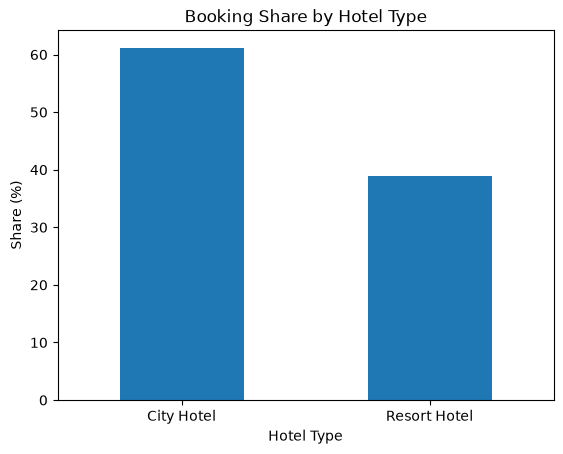

In [11]:
share = df["hotel"].value_counts(normalize=True) * 100
print(df["hotel"].value_counts())
print(share.round(2))

share.plot(kind="bar", title="Booking Share by Hotel Type", rot=0)
plt.xlabel("Hotel Type")
plt.ylabel("Share (%)")
plt.show()

**Caption:** City Hotel accounts for 61.13% of all bookings and Resort Hotel for 38.87%. City Hotel is the more frequently booked type, ahead of Resort Hotel by about 22 percentage points.

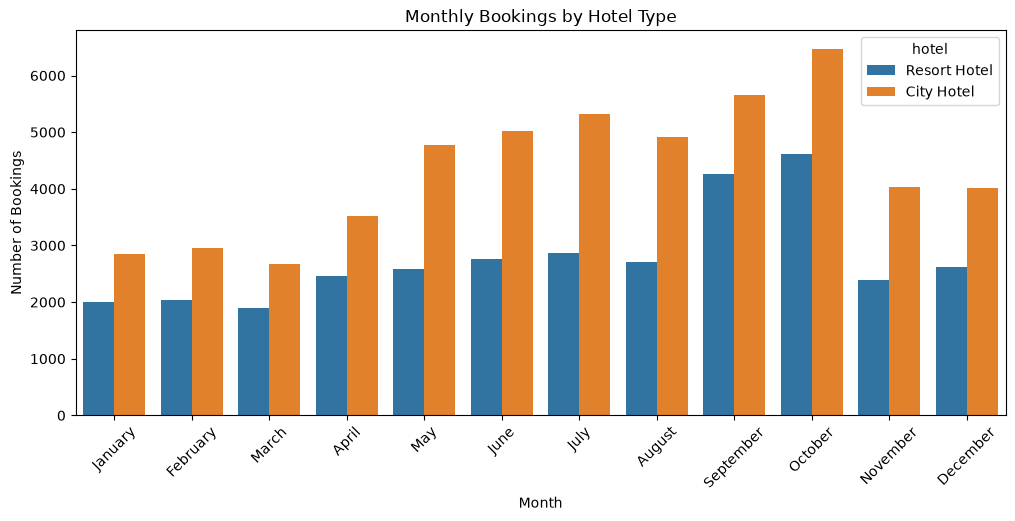

In [12]:
month_order = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]

plt.figure(figsize=(12,5))
sns.countplot(data=df, x="arrival_date_month", hue="hotel", order=month_order)
plt.title("Monthly Bookings by Hotel Type")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

In [13]:
monthly = pd.crosstab(df["arrival_date_month"], df["hotel"]).reindex(month_order)
print(monthly)
print()
print("Busiest month (total):", monthly.sum(axis=1).idxmax())
print("Quietest month (total):", monthly.sum(axis=1).idxmin())

hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                   2849          1995
February                  2952          2044
March                     2674          1904
April                     3514          2453
May                       4776          2584
June                      5017          2756
July                      5321          2863
August                    4908          2705
September                 5657          4263
October                   6473          4615
November                  4040          2386
December                  4009          2618

Busiest month (total): October
Quietest month (total): March


### 2.1 Monthly Booking Analysis

- **Busiest month:** October (11,088 bookings), followed by September (9,920).
- **Quietest month:** March (4,578 bookings), followed by January and February.
- Both hotel types follow a similar seasonal pattern: bookings are lowest from January to March and highest from May to October.

**Possible reasons for the seasonal pattern:**
- Summer and autumn see more leisure travel because of school holidays and pleasant weather.
- City Hotel also receives business and sightseeing visitors throughout the year, so its bookings never fall very low.
- Resort Hotel depends more on leisure travel, so its jump in peak season is sharper.
- Demand falls from January to March because of colder weather and fewer holidays.

**Business decisions based on the monthly trend:**
- Raise rates and increase staffing in peak months (September and October).
- Offer discounts, packages or corporate deals in the off-season (January to March).
- Schedule maintenance and renovation work in quiet months such as March.

**Caption:** The chart shows monthly bookings for City Hotel and Resort Hotel. October is the busiest month and March the quietest, and City Hotel has more bookings than Resort Hotel in every month.

hotel
City Hotel      30.32
Resort Hotel    23.71
Name: is_canceled, dtype: float64


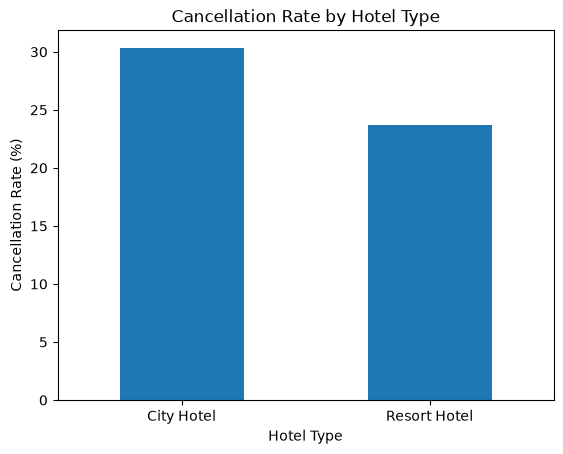

In [14]:
rate = df.groupby("hotel")["is_canceled"].mean() * 100
print(rate.round(2))

rate.plot(kind="bar", title="Cancellation Rate by Hotel Type", rot=0)
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

**Cancellation rate by hotel:** City Hotel has a cancellation rate of 30.32% and Resort Hotel 23.71%. City Hotel is cancelled more often, by about 6.6 percentage points.

**Caption:** The chart compares the overall cancellation rate of the two hotel types. City Hotel's rate is higher than Resort Hotel's.

### 2.2 Impact of Stay Duration on Cancellation Rate

hotel         City Hotel  Resort Hotel
total_nights                          
1                  22.36         12.53
2                  29.82         20.64
3                  31.40         25.71
4                  32.20         26.89
5                  30.33         30.54
6                  37.38         31.54
7                  37.67         28.31
8                  45.98         33.24
9                  43.94         32.07
10                 58.51         25.62
11                 59.21         21.72
12                 48.28         35.51
13                 62.50         26.09
14                 70.45         20.68
15                 64.86         31.25


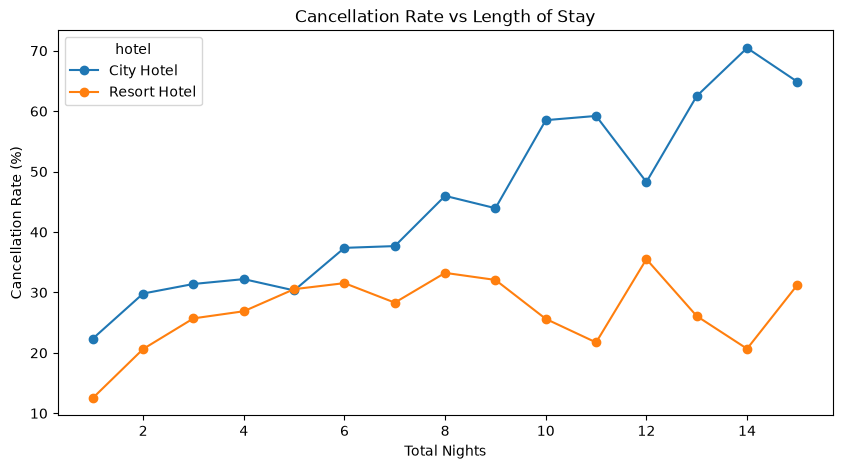

In [15]:
stay = (df[df["total_nights"] <= 15]
        .groupby(["total_nights", "hotel"])["is_canceled"].mean().mul(100)
        .unstack())

print(stay.round(2))

stay.plot(marker="o", figsize=(10,5), title="Cancellation Rate vs Length of Stay")
plt.xlabel("Total Nights")
plt.ylabel("Cancellation Rate (%)")
plt.show()

**Trend:**
- City Hotel: the cancellation rate rises steadily as the stay gets longer (22.36% for 1 night, 45.98% for 8 nights, 70.45% for 14 nights). The relationship is positive.
- Resort Hotel: the rate rises at first (12.53% for 1 night to 31.54% for 6 nights) and then stays roughly flat, between 20% and 35%.
- The two hotel types differ: the effect is strong for City Hotel and weaker for Resort Hotel.
- Note: stays longer than 10 nights are rare, so rates there are less reliable.

**Possible reasons:**
- Longer stays are more expensive and harder to plan, so guests are more likely to cancel if their leave, work or budget changes.
- Longer stays are often booked far in advance (high lead time), which gives more time for plans to change.
- Some guests book several hotels or platforms and later keep only one.

**Caption:** The chart shows the cancellation rate for stays of 1 to 15 nights. City Hotel's line rises sharply, while Resort Hotel's line fluctuates without climbing as high.

### 2.3 Impact of Lead Time on Cancellation Rate

**Lead time:** The number of days between the date a booking is made and the arrival date at the hotel.

hotel     City Hotel  Resort Hotel
lead_bin                          
0-7            10.63          6.04
8-30           28.02         20.98
31-90          33.46         29.89
91-180         36.75         32.25
181-365        45.25         34.97
365+           52.82         21.76


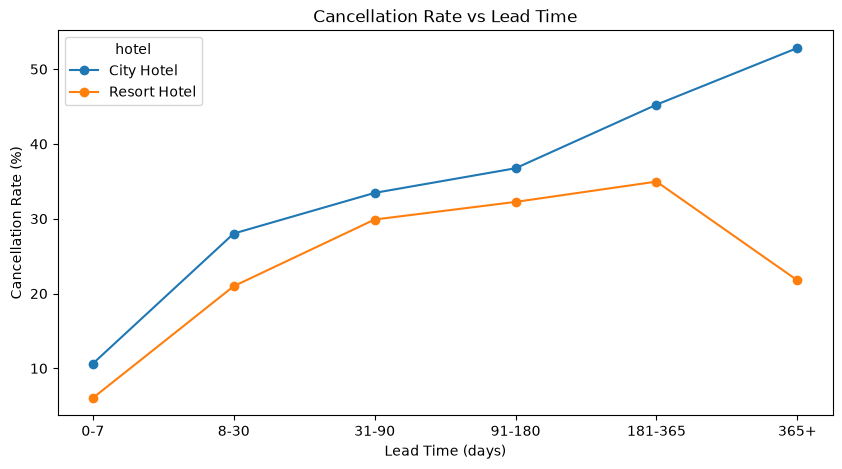

In [16]:
bins = [-1, 7, 30, 90, 180, 365, 800]
labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
df["lead_bin"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

lead = df.groupby(["lead_bin", "hotel"], observed=True)["is_canceled"].mean().mul(100).unstack()
print(lead.round(2))

lead.plot(marker="o", figsize=(10, 5), title="Cancellation Rate vs Lead Time")
plt.xlabel("Lead Time (days)")
plt.ylabel("Cancellation Rate (%)")
plt.show()

**Findings:**
- City Hotel: the cancellation rate rises steadily with lead time (10.63% for 0-7 days and 52.82% for 365+ days).
- Resort Hotel: the rate rises from 6.04% for 0-7 days to 34.97% for 181-365 days, then falls to 21.76% for 365+ days.
- Cancellations are lowest for bookings made 0-7 days before arrival, at both hotels.
- Cancellations are highest at City Hotel for bookings made 365+ days ahead (52.82%).
- Resort Hotel is more stable (its rate never exceeds 35%), while City Hotel rises sharply.

**Possible reasons:**
- City Hotel serves many business and short city trips. Plans made far ahead change more often, and free cancellation is common, so guests cancel easily.
- Resort Hotel guests usually plan vacations in advance and are more committed, so the rate rises less.
- The dip at Resort Hotel for 365+ days may reflect a different type of booking, as very early bookings are few. This could not be confirmed from the data.

**Caption:** The chart shows the cancellation rate for each lead-time group. City Hotel's line climbs steadily, while Resort Hotel's line rises more slowly and falls at the end.

In [17]:
print(df.groupby("deposit_type")["is_canceled"].mean().mul(100).round(2))
print(df["deposit_type"].value_counts())

deposit_type
No Deposit    26.95
Non Refund    94.84
Refundable    27.08
Name: is_canceled, dtype: float64
deposit_type
No Deposit    84272
Non Refund     1008
Refundable       96
Name: count, dtype: int64


## Stage 3: Summary and Recommendations

### 1. Key Findings
- **Hotel type:** City Hotel accounts for 61.13% of bookings and Resort Hotel for 38.87%, so City Hotel is the more popular type.
- **Seasonality:** October is the busiest month (11,088 bookings) and March the quietest (4,578).
- **Stay duration:** At City Hotel, the cancellation rate rises sharply as the stay gets longer (22.36% for 1 night, 45.98% for 8 nights). The effect is weaker at Resort Hotel.
- **Lead time:** At City Hotel, the cancellation rate rises from 10.63% (0-7 days) to 52.82% (365+ days). Resort Hotel is more stable.
- **Overall cancellation rate:** City Hotel 30.32%, Resort Hotel 23.71%.

### 2. Recommendations: Hotel Type and Seasonality
- **Grow Resort Hotel in the off-season:** Offer packages and discounts from January to March, when bookings are lowest.
- **Capitalise on peak months:** Raise rates and increase staffing in September and October, when demand is highest.

### 3. Recommendations: Stay Duration
- At City Hotel, require an advance payment or deposit for longer stays (more than 7 nights), where cancellations are highest.
- Offer discounts on long stays only when the booking carries strict cancellation terms.

### 4. Recommendations: Lead Time
- For bookings made far ahead (more than 90 days), send reminder emails and ask guests to reconfirm a few weeks before arrival.
- At City Hotel, apply a small deposit or less flexible cancellation terms to far-ahead bookings.

### 5. Highest-Impact Recommendation
**Introduce a deposit or reconfirmation step for far-ahead (180+ days) and long-stay bookings at City Hotel.**

*Evidence:* At City Hotel, the cancellation rate is 45.25% for lead times of 181-365 days and 52.82% for 365+ days, compared with only 10.63% for 0-7 days. The stay-duration chart shows the same pattern, with the rate rising from 22.36% for 1 night to 45.98% for 8 nights. This is where the cancellation risk is greatest, so action here would protect the most revenue.

**Note:** In the deposit data, 98.7% of bookings are "No Deposit", and Non-Refund bookings show a 94.84% cancellation rate. The reason for this cannot be confirmed from this dataset, so deposit policy is not offered here as a firm recommendation but as a measure to test.